In [1]:
import os, time                                 # os: folders, time: measure training time
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'     # allow two OpenMP copies to coexist instead of crashing
os.environ['OMP_NUM_THREADS'] = '1'             # run threaded code on one thread to avoid the clash

import numpy as np, pandas as pd               # arrays and tables
import matplotlib.pyplot as plt                # plotting
import lightgbm as lgb                         # load LightGBM BEFORE torch
import torch, torch.nn as nn                   # PyTorch for the neural models
from torch.utils.data import TensorDataset, DataLoader   # feed data to the models in batches
from sklearn.preprocessing import MinMaxScaler           # scale values to 0 to 1

SEED = 42                                      # fixed seed so results repeat
np.random.seed(SEED)                           # seed for numpy randomness
torch.manual_seed(SEED)                        # seed for PyTorch randomness
device = torch.device('cpu')                   # CPU is fast enough for these small models
os.makedirs('../results', exist_ok=True)       # make sure the results folder exists

In [2]:
cols = ['unit','cycle','op1','op2','op3'] + [f's{i}' for i in range(1,22)]   # column names

train = pd.read_csv('../data/train_FD001.txt', sep=r'\s+', header=None, names=cols)   # engines run to failure
test  = pd.read_csv('../data/test_FD001.txt',  sep=r'\s+', header=None, names=cols)   # engines cut off before failure
rul_true = pd.read_csv('../data/RUL_FD001.txt', header=None)[0].values                # true RUL at each test engine's last cycle

print(train.shape, test.shape, rul_true.shape)   # check the sizes
print(train['unit'].nunique(), test['unit'].nunique())   # number of engines in each file
print(rul_true[:10])                             # first ten true RUL values

(20631, 26) (13096, 26) (100,)
100 100
[112  98  69  82  91  93  91  95 111  96]


In [3]:
CAP = 125                                                    # RUL cap: early in life, engines show no visible damage

train['max_cycle'] = train.groupby('unit')['cycle'].transform('max')   # each row gets its engine's final cycle number
train['RUL'] = train['max_cycle'] - train['cycle']           # true remaining cycles = final cycle minus current cycle
train['RUL'] = train['RUL'].clip(upper=CAP)                  # anything above 125 is set to 125
train = train.drop(columns='max_cycle')                      # remove the helper column

print(train['RUL'].describe())                               # min should be 0 and max should be 125
print(train[train['unit'] == 1][['cycle', 'RUL']].tail(3))   # engine 1's last rows: RUL should end at 0
print(train[train['unit'] == 1][['cycle', 'RUL']].head(3))   # first rows should show RUL = 125 (capped)

count    20631.000000
mean        86.829286
std         41.673699
min          0.000000
25%         51.000000
50%        103.000000
75%        125.000000
max        125.000000
Name: RUL, dtype: float64
     cycle  RUL
189    190    2
190    191    1
191    192    0
   cycle  RUL
0      1  125
1      2  125
2      3  125


In [4]:
all_feats = ['op1', 'op2', 'op3'] + [f's{i}' for i in range(1, 22)]    # every candidate input column

const = [c for c in all_feats if train[c].std() < 1e-6]      # columns that never change carry no information
features = [c for c in all_feats if c not in const]          # keep only the informative columns

print('Dropped:', const)                                     # compare with the list you found earlier
print('Kept', len(features), 'features:', features)

Dropped: ['op3', 's1', 's5', 's10', 's16', 's18', 's19']
Kept 17 features: ['op1', 'op2', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


In [5]:
rng = np.random.RandomState(SEED)                                      # seeded random generator so the split repeats
val_units = rng.choice(train['unit'].unique(), size=20, replace=False) # pick 20 engine ids at random, no repeats

tr_df = train[~train['unit'].isin(val_units)].copy()   # training set: the other 80 engines
va_df = train[train['unit'].isin(val_units)].copy()    # validation set: the 20 held-out engines
te_df = test.copy()                                    # test set: stays untouched

print('Train engines:', tr_df['unit'].nunique())       # should be 80
print('Validation engines:', va_df['unit'].nunique())  # should be 20
print('Overlap:', set(tr_df['unit']) & set(va_df['unit']))   # must print set(), meaning no engine is in both

Train engines: 80
Validation engines: 20
Overlap: set()


In [6]:
scaler = MinMaxScaler().fit(tr_df[features])           # learn each column's min and max from TRAINING engines only

tr_df[features] = scaler.transform(tr_df[features])    # apply to training data
va_df[features] = scaler.transform(va_df[features])    # apply the same scaling to validation
te_df[features] = scaler.transform(te_df[features])    # and to test

print(tr_df[features].min().min(), tr_df[features].max().max())   # should print 0.0 and 1.0
print(va_df[features].min().min(), va_df[features].max().max())   # may be slightly outside 0 to 1, which is normal

0.0 1.0
-0.05222024866785091 1.0059880239520957


In [7]:
WIN = 30                                                  # each sample covers 30 consecutive cycles

def make_windows(df):                                     # builds labelled windows for training and validation
    X, y = [], []                                         # lists to collect windows and their labels
    for u, g in df.groupby('unit'):                       # handle one engine at a time, so windows never cross engines
        a = g[features].values.astype(np.float32)         # this engine's feature values as an array
        r = g['RUL'].values.astype(np.float32)            # this engine's RUL values
        for i in range(WIN - 1, len(g)):                  # the window ends at row i, starting from the 30th cycle
            X.append(a[i - WIN + 1 : i + 1])              # the 30 rows ending at i
            y.append(r[i])                                # the label is the RUL at the window's last cycle
    return np.stack(X), np.array(y, dtype=np.float32)     # stack into one array

def last_windows(df):                                     # builds ONE window per test engine: its final 30 cycles
    X = []
    for u, g in df.groupby('unit'):
        a = g[features].values.astype(np.float32)
        if len(a) < WIN:                                  # if the engine has fewer than 30 cycles...
            a = np.vstack([np.repeat(a[:1], WIN - len(a), axis=0), a])   # ...pad the start by repeating its first row
        X.append(a[-WIN:])                                # take the last 30 rows
    return np.stack(X)

In [8]:
Xtr, ytr = make_windows(tr_df)                            # training windows and labels
Xva, yva = make_windows(va_df)                            # validation windows and labels
Xte = last_windows(te_df)                                 # test windows (one per engine)

print('Xtr', Xtr.shape, 'ytr', ytr.shape)                 # (number of windows, 30, number of features)
print('Xva', Xva.shape, 'yva', yva.shape)
print('Xte', Xte.shape)                                   # should be (100, 30, number of features)

print('Check train count:', len(tr_df) - (WIN - 1) * tr_df['unit'].nunique() == Xtr.shape[0])   # must print True
print('Check val count  :', len(va_df) - (WIN - 1) * va_df['unit'].nunique() == Xva.shape[0])   # must print True
print('Labels range     :', ytr.min(), ytr.max())         # should be 0.0 and 125.0
print('Short test engines:', (te_df.groupby('unit').size() < WIN).sum())   # how many test engines needed padding

Xtr (14241, 30, 17) ytr (14241,)
Xva (3490, 30, 17) yva (3490,)
Xte (100, 30, 17)
Check train count: True
Check val count  : True
Labels range     : 0.0 125.0
Short test engines: 0


In [9]:
def rmse(y, p):                                           # root mean squared error, in cycles
    return float(np.sqrt(np.mean((p - y) ** 2)))          # square the errors, average them, take the square root

def nasa_score(y, p):                                     # the asymmetric NASA score: lower is better
    d = p - y                                             # error; positive means we predicted too much life left
    return float(np.sum(np.where(d < 0,
                                 np.exp(-d / 13) - 1,     # early predictions are punished gently
                                 np.exp(d / 10) - 1)))    # late predictions are punished harder

In [10]:
def summarize(X):                                         # turn each (30, 17) window into one flat row
    return np.concatenate([
        X[:, -1, :],                                      # the latest value of each feature
        X.mean(axis=1),                                   # the average over the window
        X.std(axis=1),                                    # how much it varied over the window
        X[:, -1, :] - X[:, 0, :]                          # the trend: last value minus first value
    ], axis=1)                                            # join them side by side: 17 x 4 = 68 columns

Ftr, Fva, Fte = summarize(Xtr), summarize(Xva), summarize(Xte)   # flat features for each set
print('Flat feature shapes:', Ftr.shape, Fva.shape, Fte.shape)   # expect 68 columns in each

gbm = lgb.LGBMRegressor(
    n_estimators=1000,                                    # allow up to 1000 trees...
    learning_rate=0.03,                                   # ...each making a small correction
    num_leaves=31,                                        # complexity of each tree
    subsample=0.8, subsample_freq=1,                      # each tree sees 80% of the rows
    colsample_bytree=0.8,                                 # each tree sees 80% of the columns
    random_state=SEED, verbose=-1)                        # fixed seed and quiet output

gbm.fit(Ftr, ytr,
        eval_set=[(Fva, yva)],                            # watch the validation engines
        callbacks=[lgb.early_stopping(50, verbose=False)])   # stop when validation stops improving for 50 rounds

p_gbm = np.clip(gbm.predict(Fte), 0, CAP)                 # predict test engines, keep results within 0 to 125
print('Trees used:', gbm.best_iteration_)                 # how many trees early stopping kept
print('LightGBM  RMSE:', round(rmse(rul_true, p_gbm), 2), ' NASA score:', round(nasa_score(rul_true, p_gbm), 1))

Flat feature shapes: (14241, 68) (3490, 68) (100, 68)


/Users/shayan/Developer/rul-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Trees used: 189
LightGBM  RMSE: 16.53  NASA score: 483.5


In [11]:
class CNN1D(nn.Module):                                       # 1D convolutional network over the 30-cycle window
    def __init__(self, n_feat, win):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(n_feat, 64, 3, padding=1), nn.ReLU(),   # slide a size-3 filter over time to find short patterns
            nn.Conv1d(64, 64, 3, padding=1), nn.ReLU(),       # a second layer finds patterns of patterns
            nn.Flatten(), nn.Dropout(0.2),                    # flatten to one vector; dropout reduces overfitting
            nn.Linear(64 * win, 64), nn.ReLU(),               # combine everything into 64 numbers
            nn.Linear(64, 1))                                 # output: one RUL value
    def forward(self, x):                                     # x has shape (batch, window, features)
        return self.net(x.transpose(1, 2)).squeeze(1)         # Conv1d wants (batch, features, window), so swap axes

class GRUNet(nn.Module):                                      # GRU: a recurrent network that reads the window in order
    def __init__(self, n_feat, hidden=64):
        super().__init__()
        self.gru = nn.GRU(n_feat, hidden, num_layers=2, batch_first=True, dropout=0.2)   # two stacked GRU layers
        self.head = nn.Sequential(nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1))    # small output network
    def forward(self, x):
        out, _ = self.gru(x)                                  # out has shape (batch, window, hidden)
        return self.head(out[:, -1, :]).squeeze(1)            # use the last time step to predict RUL

In [12]:
def predict(model, X):                                        # run a trained model on a numpy array
    model.eval()                                              # switch off dropout
    with torch.no_grad():                                     # no gradients needed for prediction
        return model(torch.tensor(X).to(device)).cpu().numpy()

def train_model(model, Xt, yt, Xv, yv, epochs=60, lr=1e-3, bs=256, patience=10):
    model.to(device)
    dl = DataLoader(TensorDataset(torch.tensor(Xt), torch.tensor(yt)), batch_size=bs, shuffle=True)   # mini-batches
    Xv_t, yv_t = torch.tensor(Xv).to(device), torch.tensor(yv).to(device)     # validation data as tensors
    opt = torch.optim.Adam(model.parameters(), lr=lr)         # Adam optimizer
    loss_fn = nn.MSELoss()                                    # mean squared error loss
    best, bad, best_state = 1e9, 0, None                      # track the best validation error so far
    for ep in range(epochs):
        model.train()                                         # switch dropout on
        for xb, yb in dl:                                     # one pass over all training batches
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()                                   # clear old gradients
            loss_fn(model(xb), yb).backward()                 # compute the error and its gradients
            opt.step()                                        # update the weights
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(Xv_t), yv_t).item() ** 0.5     # validation RMSE (in scaled units)
        if vl < best:                                         # new best result: remember these weights
            best, bad = vl, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break                         # stop early if no improvement for 10 epochs
        if ep % 5 == 0: print(f'epoch {ep}  val RMSE {vl * CAP:.2f}')   # progress, converted back to cycles
    model.load_state_dict(best_state)                         # restore the best weights, not the last
    return model

In [13]:
n_feat = len(features)                                        # should be 17
cnn, gru = CNN1D(n_feat, WIN), GRUNet(n_feat)                 # create untrained models

sample = torch.tensor(Xtr[:5])                                # five training windows
print('Input shape :', sample.shape)                          # (5, 30, 17)
print('CNN output  :', cnn(sample).shape)                     # should be torch.Size([5])
print('GRU output  :', gru(sample).shape)                     # should be torch.Size([5])
print('CNN parameters:', sum(p.numel() for p in cnn.parameters()))   # size of each model
print('GRU parameters:', sum(p.numel() for p in gru.parameters()))

Input shape : torch.Size([5, 30, 17])
CNN output  : torch.Size([5])
GRU output  : torch.Size([5])
CNN parameters: 138689
GRU parameters: 43009


In [14]:
rows = [{'model': 'LightGBM', 'seed': SEED, 'RMSE': rmse(rul_true, p_gbm),
         'NASA': nasa_score(rul_true, p_gbm), 'sec': np.nan}]        # start the results table with the baseline
preds = {'LightGBM': p_gbm}                                          # store each model's test predictions

torch.manual_seed(0); np.random.seed(0)                              # seed for this run
t0 = time.time()                                                     # start the timer
cnn = train_model(CNN1D(n_feat, WIN), Xtr, ytr / CAP, Xva, yva / CAP)   # train on targets scaled to 0 to 1
p_cnn = np.clip(predict(cnn, Xte) * CAP, 0, CAP)                     # predict test engines and convert back to cycles

rows.append({'model': 'CNN1D', 'seed': 0, 'RMSE': rmse(rul_true, p_cnn),
             'NASA': nasa_score(rul_true, p_cnn), 'sec': time.time() - t0})
preds['CNN1D'] = p_cnn
print('CNN1D  RMSE:', round(rows[-1]['RMSE'], 2), ' NASA:', round(rows[-1]['NASA'], 1), ' time:', round(rows[-1]['sec']), 's')

epoch 0  val RMSE 19.57
epoch 5  val RMSE 12.89
epoch 10  val RMSE 12.63
CNN1D  RMSE: 15.42  NASA: 354.4  time: 39 s


In [15]:
torch.manual_seed(0); np.random.seed(0)                              # same seed for a fair comparison
t0 = time.time()
gru = train_model(GRUNet(n_feat), Xtr, ytr / CAP, Xva, yva / CAP)
p_gru = np.clip(predict(gru, Xte) * CAP, 0, CAP)

rows.append({'model': 'GRU', 'seed': 0, 'RMSE': rmse(rul_true, p_gru),
             'NASA': nasa_score(rul_true, p_gru), 'sec': time.time() - t0})
preds['GRU'] = p_gru
print('GRU    RMSE:', round(rows[-1]['RMSE'], 2), ' NASA:', round(rows[-1]['NASA'], 1), ' time:', round(rows[-1]['sec']), 's')

epoch 0  val RMSE 22.93
epoch 5  val RMSE 13.80
epoch 10  val RMSE 13.75
epoch 15  val RMSE 12.11
epoch 20  val RMSE 12.59
GRU    RMSE: 15.17  NASA: 390.9  time: 21 s


In [16]:
results = pd.DataFrame(rows)                                         # one row per model
results.to_csv('../results/fd001_results.csv', index=False)          # save it for your report
print(results.round(2))                                              # show it

      model  seed   RMSE    NASA    sec
0  LightGBM    42  16.53  483.51    NaN
1     CNN1D     0  15.42  354.38  38.60
2       GRU     0  15.17  390.91  20.67


In [17]:
from sklearn.linear_model import Ridge                       # linear baseline
from sklearn.ensemble import RandomForestRegressor           # tree ensemble baseline

def add_row(name, seed, p, sec=np.nan):                      # helper: score predictions and add a results row
    rows.append({'model': name, 'seed': seed, 'RMSE': rmse(rul_true, p),
                 'NASA': nasa_score(rul_true, p), 'sec': sec})
    print(name, 'seed', seed, '-> RMSE', round(rows[-1]['RMSE'], 2), ' NASA', round(rows[-1]['NASA'], 1))

t0 = time.time()
ridge = Ridge(alpha=1.0).fit(Ftr, ytr)                       # linear regression on the 68 summary features
p_ridge = np.clip(ridge.predict(Fte), 0, CAP)
add_row('Ridge', 0, p_ridge, time.time() - t0); preds['Ridge'] = p_ridge

t0 = time.time()
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                           random_state=SEED, n_jobs=1).fit(Ftr, ytr)   # 300 trees, one thread (avoids the earlier crash)
p_rf = np.clip(rf.predict(Fte), 0, CAP)
add_row('RandomForest', SEED, p_rf, time.time() - t0); preds['RandomForest'] = p_rf

Ridge seed 0 -> RMSE 17.9  NASA 542.4
RandomForest seed 42 -> RMSE 17.89  NASA 598.8


In [18]:
def run_gbm(seed):                                           # LightGBM with a different seed
    g = lgb.LGBMRegressor(n_estimators=1000, learning_rate=0.03, num_leaves=31, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=seed, n_jobs=1, verbose=-1)
    g.fit(Ftr, ytr, eval_set=[(Fva, yva)], callbacks=[lgb.early_stopping(50, verbose=False)])
    return np.clip(g.predict(Fte), 0, CAP)

def run_rf(seed):                                            # Random Forest with a different seed
    r = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                              random_state=seed, n_jobs=1).fit(Ftr, ytr)
    return np.clip(r.predict(Fte), 0, CAP)

def run_nn(maker, seed):                                     # a neural model with a different seed
    torch.manual_seed(seed); np.random.seed(seed)
    m = train_model(maker(), Xtr, ytr / CAP, Xva, yva / CAP)
    return np.clip(predict(m, Xte) * CAP, 0, CAP)

for s in [1, 2]:                                             # seed 0 (or 42) already done above
    for name, fn in [('LightGBM', lambda: run_gbm(s)), ('RandomForest', lambda: run_rf(s)),
                     ('CNN1D', lambda: run_nn(lambda: CNN1D(n_feat, WIN), s)),
                     ('GRU', lambda: run_nn(lambda: GRUNet(n_feat), s))]:
        t0 = time.time()
        add_row(name, s, fn(), time.time() - t0)

/Users/shayan/Developer/rul-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM seed 1 -> RMSE 16.8  NASA 479.4
RandomForest seed 1 -> RMSE 17.87  NASA 609.4
epoch 0  val RMSE 20.05
epoch 5  val RMSE 13.05
epoch 10  val RMSE 13.19
epoch 15  val RMSE 12.57
epoch 20  val RMSE 12.45
CNN1D seed 1 -> RMSE 14.82  NASA 309.5
epoch 0  val RMSE 20.72
epoch 5  val RMSE 13.25
epoch 10  val RMSE 12.02
epoch 15  val RMSE 11.93
epoch 20  val RMSE 11.97
GRU seed 1 -> RMSE 14.76  NASA 367.5


/Users/shayan/Developer/rul-project/.venv/lib/python3.14/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


LightGBM seed 2 -> RMSE 16.65  NASA 475.3
RandomForest seed 2 -> RMSE 17.85  NASA 599.3
epoch 0  val RMSE 18.93
epoch 5  val RMSE 12.68
epoch 10  val RMSE 12.71
epoch 15  val RMSE 12.79
epoch 20  val RMSE 12.52
CNN1D seed 2 -> RMSE 14.91  NASA 336.5
epoch 0  val RMSE 26.06
epoch 5  val RMSE 12.85
epoch 10  val RMSE 12.07
epoch 15  val RMSE 12.33
epoch 20  val RMSE 12.19
epoch 25  val RMSE 11.77
epoch 30  val RMSE 11.90
GRU seed 2 -> RMSE 14.57  NASA 346.5


In [19]:
results = pd.DataFrame(rows)                                 # every run so far
results.to_csv('../results/fd001_all_runs.csv', index=False) # save every run

summary = results.groupby('model')[['RMSE', 'NASA']].agg(['mean', 'std', 'min', 'max']).round(2)   # mean and spread per model
summary = summary.sort_values(('RMSE', 'mean'))              # best model first
summary.to_csv('../results/fd001_summary.csv')               # save for the report
print(summary)
print(results.groupby('model').size())                       # runs per model: Ridge has 1 (deterministic), the rest have 3

               RMSE                        NASA                       
               mean   std    min    max    mean    std     min     max
model                                                                 
GRU           14.84  0.31  14.57  15.17  368.29  22.23  346.46  390.91
CNN1D         15.05  0.32  14.82  15.42  333.46  22.60  309.49  354.38
LightGBM      16.66  0.14  16.53  16.80  479.40   4.12  475.28  483.51
RandomForest  17.87  0.02  17.85  17.89  602.48   5.97  598.81  609.36
Ridge         17.90   NaN  17.90  17.90  542.38    NaN  542.38  542.38
model
CNN1D           3
GRU             3
LightGBM        3
RandomForest    3
Ridge           1
dtype: int64


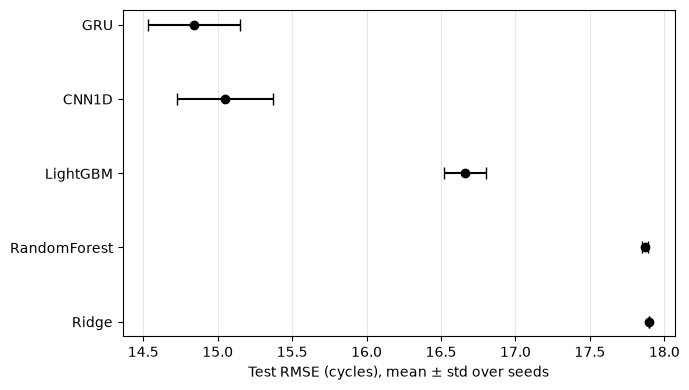

In [20]:
means = summary[('RMSE', 'mean')]                          # mean RMSE per model
stds = summary[('RMSE', 'std')].fillna(0)                  # Ridge has one run, so no error bar
plt.figure(figsize=(7, 4))
plt.errorbar(means.values, range(len(means)), xerr=stds.values, fmt='o', color='black', capsize=4)
plt.yticks(range(len(means)), means.index)                 # model names on the y-axis
plt.gca().invert_yaxis()                                   # best model at the top
plt.xlabel('Test RMSE (cycles), mean ± std over seeds')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../results/model_comparison.png', dpi=150)
plt.show()

In [21]:
import json, joblib
os.makedirs('../models', exist_ok=True)                    # folder for saved artifacts
torch.save(gru.state_dict(), '../models/gru_fd001.pt')     # the GRU's learned weights
joblib.dump(scaler, '../models/scaler_fd001.joblib')       # the exact scaler used in training
with open('../models/config_fd001.json', 'w') as f:        # settings the dashboard must reuse
    json.dump({'features': features, 'WIN': WIN, 'CAP': CAP, 'hidden': 64, 'n_feat': n_feat}, f)
print(os.listdir('../models'))                             # expect three files

['gru_fd001.pt', 'config_fd001.json', 'scaler_fd001.joblib']
